In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

In [24]:
# read and process dataset

# path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx - TextReading_Included.csv"
# df = pd.read_csv(path, usecols={"topic": str, "Title": str, "Year": int, "Source": str})

# path = r"data\src\conflated_database___2026_03_31__11_14_35 (1).xlsx"
# path = r"data\src\conflated_database___2026_03_31__11_14_35 (2).xlsx"
# path = r"data\src\conflated_database___2026_03_31__11_14_35 (3).xlsx"
# path = r"data\src\conflated_database___2026_03_31__11_14_35 (4).xlsx"
path = r"data\src\conflated_database___2026_03_31__11_14_35 (5).xlsx"
df = pd.read_excel(path, sheet_name="TextReading_Included")

df = df[df.topic.notna()]
df.reset_index(drop=True, inplace=True)

df.topic = df.topic.apply(lambda x: x.split(", "))
df.Year = df.Year.astype(int)
df

,topic,Detailed GP,Title,Year,Source,Unnamed: 5,Pre processing outside generative model,Core Generative Paradigm,Dataset,Conditioning Regimes,...,Post processing outside generative model,Ultimate Output elements,Generalizability,User Studies,AF: Human-likeness,AF: Alignment-to-input,AF: Normative compliance,AF: Intrinsic,COMBINED,Ablation study (none if empty)
0,"[Model, Dataset, Evaluation]",Discriminators,Complex layout generation for large-scale floo...,2025,Scopus,NaN,Graph retriever,Discriminative,"RPLAN, P-PLAN",all,...,"Geometry alignment, Opening placement",room function and contour,Absent,Absent,Pixel-level accuracy?,Absent,Absent,"RAI (Room Accessibility Index), Space Property...",NaN,yes
1,"[Model, Dataset]",NaN,Automated building layout generation using dee...,2023,Scopus,NaN,"Graph retriever, Graph refiner",Discriminative,GeLayout,all,...,Absent,walls,Absent,Intrinsic evaluation,"IoU, mIoU, Pixel-level accuracy?",Absent,Absent,Absent,NaN,NaN
2,[Model],NaN,FLNet: Graph Constrained Floor Layout Generation,2022,Scopus,NaN,Absent,Discriminative,RPLAN,all,...,Absent,"room function and contour, walls, entrance doo...",Absent,Realism,"FID (Quality), IoU",Absent,Absent,Absent,NaN,NaN
3,[Model],NaN,Skip-Connected Neural Networks with Layout Gra...,2023,arXiv,NaN,Absent,Discriminative,MSD,all,...,Absent,"room function and contour, walls",Absent,Absent,IoU (CVAAD),Absent,Absent,Absent,NaN,NaN
4,[Model],Discriminators (Stacked),FlexPlan: High-flexibility interactive floorpl...,2025,Scopus,NaN,Floorplan retriever,Discriminative,RPLAN,all,...,"Geometry alignment, Opening placement","room function and contour, walls, interior doo...",test on other data: non-manhattan geometry,Intrinsic evaluation,FID (Similarity),Absent,Absent,Absent,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,[Dataset],NaN,MSD: A Benchmark Dataset for Floor Plan Genera...,2025,Scopus,NaN,Absent,Multiple Models,MSD,Multiple Models,...,Multiple Models,Multiple Models,Absent,Absent,"Mean IoU, Graph Compatibility",Absent,Absent,Absent,NaN,yes
68,"[Dataset, Evaluation]",NaN,The impact of architecturally qualified data i...,2024,Scopus,NaN,Absent,Multiple Models,"RPLAN, PUBLICPLAN",Multiple Models,...,Multiple Models,Multiple Models,Absent,"Realism, Ranking",Absent,Absent,Absent,Absent,NaN,NaN
69,[Evaluation],NaN,The Possibilities of Text-to-Image Tools for t...,2024,Scopus,NaN,Absent,Diffusion,Custom,all,...,Absent,"room function and contour, walls, interior doo...",Absent,Absent,Absent,Absent,Absent,Absent,NaN,NaN
70,[Evaluation],NaN,Quality assessment of residential layout desig...,2024,Scopus,NaN,Absent,GAN,RPLAN,all,...,Absent,"room function and contour, walls, interior doo...",Absent,Absent,"U test (room size proportions), U test (Visual...",Absent,Absent,Percent of isolated rooms,NaN,NaN


# RESULTS

### QUANTITY

In [25]:
# Figure: papers per Year

counts = df.groupby(['Year', 'Source']).size().unstack(fill_value=0)
counts = counts.sort_index()
counts

Source,Scopus,arXiv
Year,,
2019,1,0
2020,4,0
2021,1,0
2022,7,0
2023,8,4
2024,17,4
2025,24,2


<Axes: xlabel='Year', ylabel='# papers'>

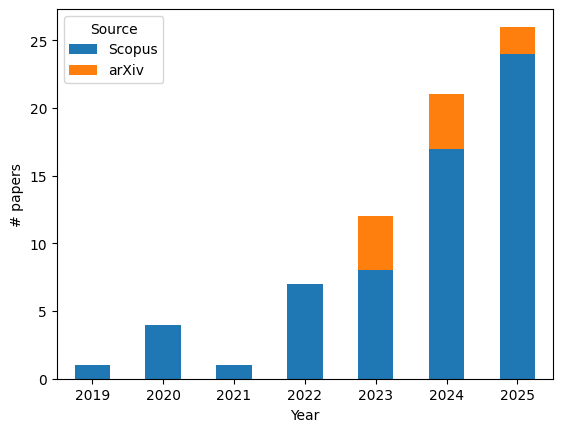

In [26]:
counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)

In [28]:
# Novelty

df.topic.value_counts().sort_index()

topic
[Dataset]                        1
[Dataset, Evaluation]            1
[Evaluation]                     5
[Model]                         54
[Model, Dataset]                 7
[Model, Dataset, Evaluation]     3
[Model, Evaluation]              1
Name: count, dtype: int64

### MODEL

In [29]:
df["Core Generative Paradigm"].value_counts()

Core Generative Paradigm
Diffusion                              22
GAN                                    20
Discriminative                         10
Autoregressive                          9
Multiple Models                         4
Hybrid: Discriminative+ABM              1
Hybrid: Discriminative+Optimization     1
Hybrid: GAN+Diffusion                   1
Hybrid: Diffusion+GA                    1
Hybrid: VAE+Autoregressive+RL           1
Hybrid: Normalizing Flow+RL             1
VAE                                     1
Name: count, dtype: int64

In [30]:
df_model = df[df.topic.apply(lambda x: "Model" in x)]
df_model["Core Generative Paradigm Groups"] = \
df_model["Core Generative Paradigm"].apply(lambda x: "Hybrid" if "Hybrid" in x else x)
df_model["Core Generative Paradigm Groups"].value_counts()

Core Generative Paradigm Groups
Diffusion         21
GAN               18
Discriminative    10
Autoregressive     9
Hybrid             6
VAE                1
Name: count, dtype: int64

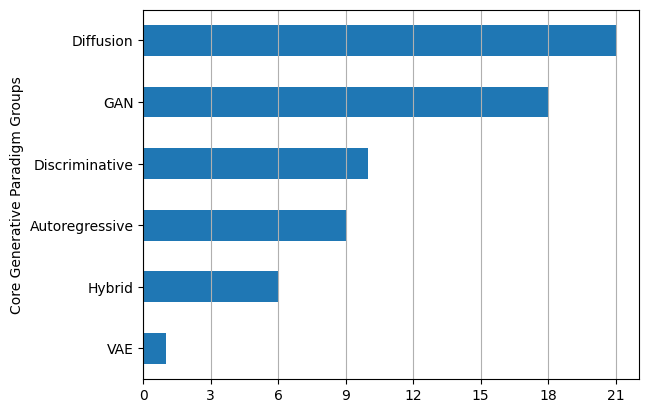

In [31]:
ax = df_model["Core Generative Paradigm Groups"].value_counts(ascending=True).plot(
    kind="barh",
)
ax.grid(axis="x")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

<Axes: >

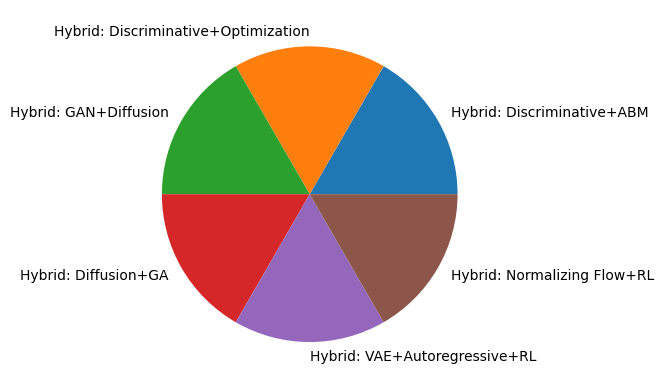

In [32]:
df_hybrid = df_model[df_model["Core Generative Paradigm Groups"] == "Hybrid"]
df_hybrid["Core Generative Paradigm"].value_counts().plot(kind="pie")

In [33]:
model_counts = df_model.groupby(['Year', 'Core Generative Paradigm Groups']).size().unstack(fill_value=0)
model_counts = model_counts.sort_index()
model_counts

Core Generative Paradigm Groups,Autoregressive,Diffusion,Discriminative,GAN,Hybrid,VAE
Year,,,,,,
2019,0,0,1,0,0,0
2020,0,0,2,2,0,0
2021,0,0,0,1,0,0
2022,2,0,1,3,0,0
2023,2,3,2,4,1,0
2024,3,9,1,4,1,0
2025,2,9,3,4,4,1


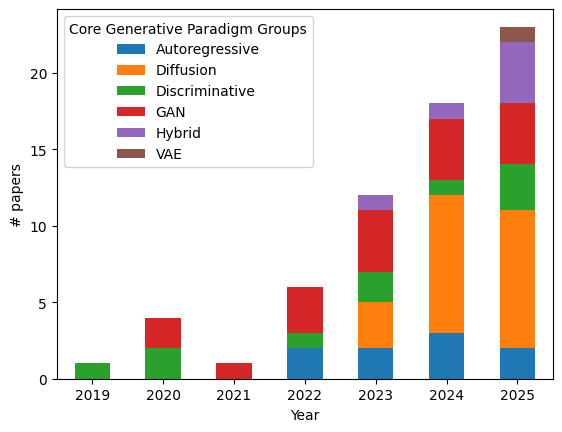

In [34]:
ax = model_counts.plot(
    kind='bar',
    stacked=True,
    rot=0,
    ylabel="# papers"
)
# ax.grid(axis="y")

### POST PROCESSING

<Axes: >

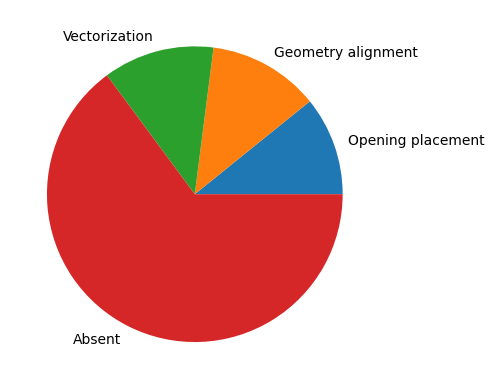

In [35]:
df_model["postprocessing"] = df_model["Post processing outside generative model"].apply(lambda x: x.split(", "))
df_model["postprocessing"].explode().value_counts(ascending=True).plot(kind="pie")

### PRE PROCESSING

<Axes: >

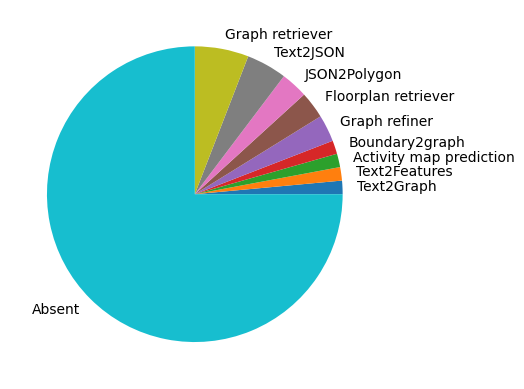

In [36]:
df_model["preprocessing"] = df_model["Pre processing outside generative model"].apply(lambda x: x.split(", "))
df_model["preprocessing"].explode().value_counts(ascending=True).plot(kind="pie")

In [37]:
df_model["preprocessing"].explode().value_counts(ascending=True)

preprocessing
Text2Graph                  1
Text2Features               1
Activity map prediction     1
Boundary2graph              1
Graph refiner               2
Floorplan retriever         2
JSON2Polygon                2
Text2JSON                   3
Graph retriever             4
Absent                     51
Name: count, dtype: int64

In [ ]:
///

### DATASET

<Axes: ylabel='dataset'>

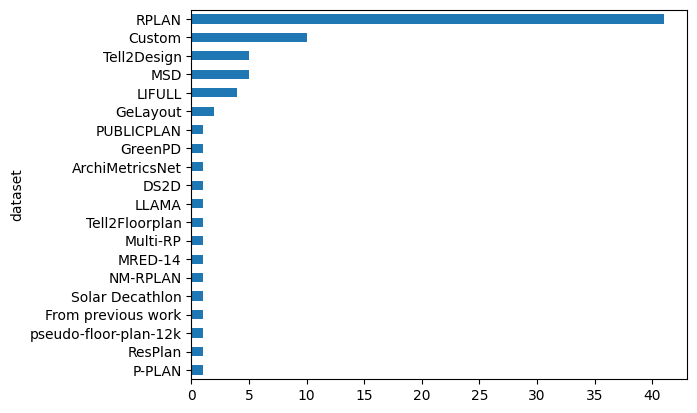

In [38]:
df["dataset"] = df["Dataset"].apply(lambda x: x.split(", "))
df["dataset"].explode().value_counts(ascending=True).plot(kind="barh")

In [39]:
df["Generalizability"]

0                                                Absent
1                                                Absent
2                                                Absent
3                                                Absent
4            test on other data: non-manhattan geometry
                            ...                        
67                                               Absent
68                                               Absent
69                                               Absent
70                                               Absent
71    cross-validation: timeseries, cross-validation...
Name: Generalizability, Length: 72, dtype: str

### GENERALIZABILITY

<Axes: ylabel='Level1'>

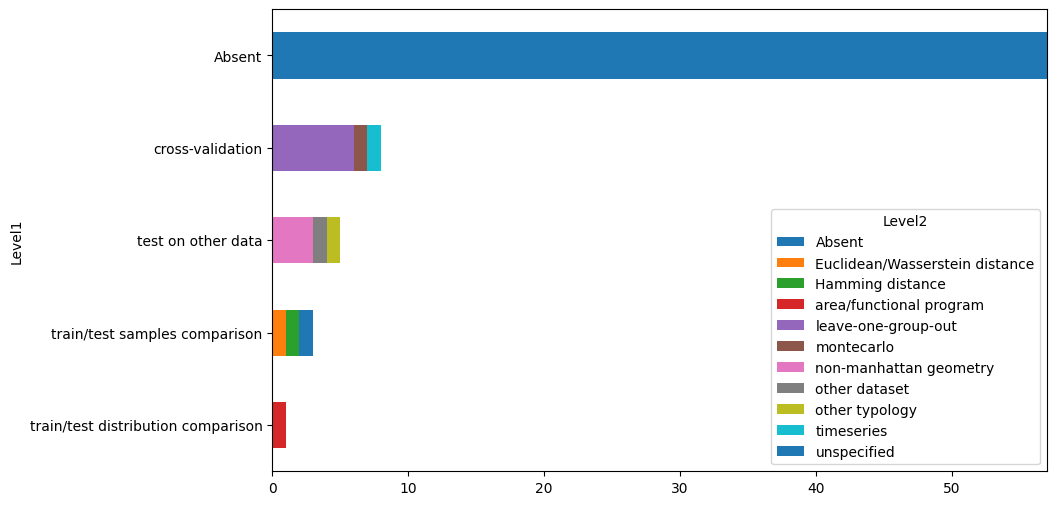

In [40]:
def split_levels(x):
    if ':' in x:
        l1, l2 = x.split(':', 1)
        return pd.Series([l1.strip(), l2.strip()])
    else:
        return pd.Series([x.strip(), None])

df["generalizability"] = df["Generalizability"].apply(lambda x: x.split(", "))

exploded = df["generalizability"].explode()
exploded = exploded.apply(split_levels)
exploded.columns = ['Level1', 'Level2']
exploded['Level2'] = exploded['Level2'].fillna('Absent')

g_counts = exploded.groupby(['Level1', 'Level2']).size().unstack(fill_value=0)
totals = g_counts.sum(axis=1)
g_counts = g_counts.loc[totals.sort_values(ascending=True).index]

g_counts.plot(
    kind='barh',
    stacked=True,
    figsize=(10,6)
)
